<a href="https://colab.research.google.com/github/Tsadza323/assignment-5-for-week-5/blob/main/week_6_assignment_6s.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df= pd.read_csv("/content/Reference_geotherm2Dmodel_base (1).csv")
df.head()

,pres,temp,x,z,log10PER
0,9635610.0,82.126015,10,-990,-14.190209
1,9635685.0,82.074013,30,-990,-14.193206
2,9635831.0,81.971626,50,-990,-14.193851
3,9636048.0,81.821793,70,-990,-14.195125
4,9636333.0,81.628616,90,-990,-14.200741


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#Import libraries#

In [ ]:
df.head()

,pres,temp,x,z,log10PER
0,9635610.0,82.126015,10,-990,-14.190209
1,9635685.0,82.074013,30,-990,-14.193206
2,9635831.0,81.971626,50,-990,-14.193851
3,9636048.0,81.821793,70,-990,-14.195125
4,9636333.0,81.628616,90,-990,-14.200741


In [ ]:
print (df.shape)
print(df.columns)
print(df.dtypes)

(2500, 5)
Index(['pres', 'temp', 'x', 'z', 'log10PER'], dtype='object')
pres        float64
temp        float64
x             int64
z             int64
log10PER    float64
dtype: object


In [26]:

numeric_columns=df.select_dtypes(include =np.number).columns.tolist()

print("Available numerical features:")
print(numeric_columns)
#Selecting features for clustering#

Available numerical features:
['pres', 'temp', 'x', 'z', 'log10PER']


In [27]:
features= ['pres', 'temp', 'x', 'z', 'log10PER']

In [28]:
X=df[features].copy()
#Replace infinite values with missing values#
X=X.replace([np.inf, -np.inf], np.nan)
#Remove rows with missing feature values#
X=X.dropna()
#Scale the features#
scaler= StandardScaler()
X_scaled= scaler.fit_transform(X)

print("Data shape after preparation:", X_scaled.shape)








Data shape after preparation: (2500, 5)


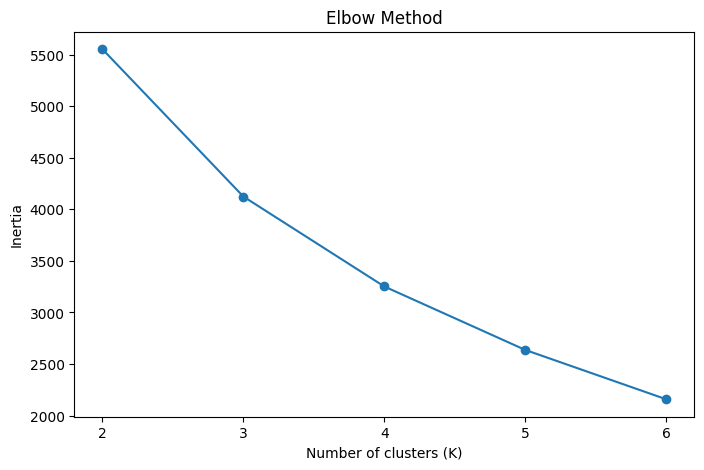

In [31]:
inertia_values = []
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    # fit_predict already fits the model and returns the labels in one go
    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plot the elbow graph
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.show()

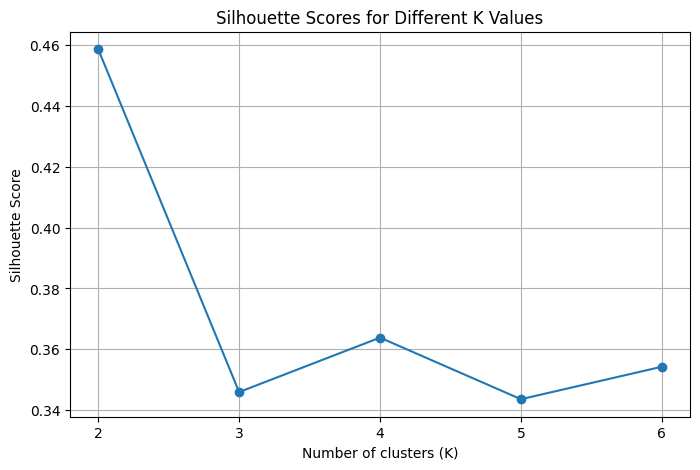

K = 2: Silhouette score = 0.459
K = 3: Silhouette score = 0.346
K = 4: Silhouette score = 0.364
K = 5: Silhouette score = 0.344
K = 6: Silhouette score = 0.354


In [34]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Different K Values')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

for k, score in zip(k_values, silhouette_scores):
    print(f"K = {k}: Silhouette score = {score:.3f}")

In [37]:
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original data
clustered_data = df.loc[X.index].copy()
clustered_data['Cluster'] = cluster_labels

print(clustered_data.head())

        pres       temp   x    z   log10PER  Cluster
0  9635610.0  82.126015  10 -990 -14.190209        0
1  9635685.0  82.074013  30 -990 -14.193206        0
2  9635831.0  81.971626  50 -990 -14.193851        0
3  9636048.0  81.821793  70 -990 -14.195125        0
4  9636333.0  81.628616  90 -990 -14.200741        0


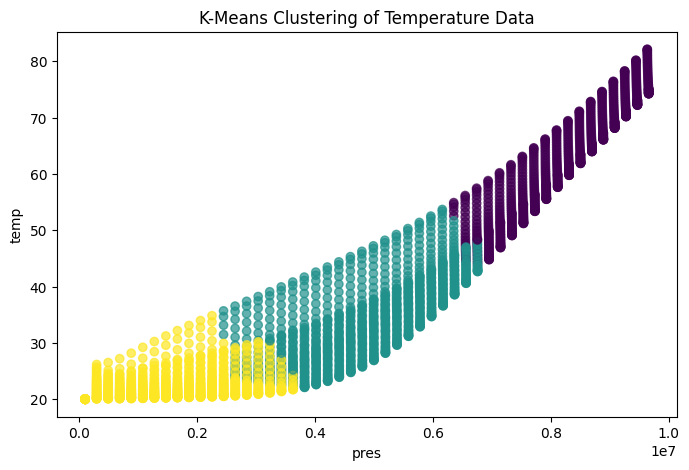

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=cluster_labels,
    cmap='viridis',
    alpha=0.7
)

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title('K-Means Clustering of Temperature Data')
plt.show()

In [39]:
cluster_summary = clustered_data.groupby('Cluster')[features].mean()

print(cluster_summary.round(2))

               pres   temp       x       z  log10PER
Cluster                                             
0        8178483.00  62.12  483.33 -837.33    -13.94
1        4807317.63  34.21  480.95 -490.72    -12.68
2        1562804.63  22.38  539.76 -159.24    -11.04


In [40]:
print(clustered_data['Cluster'].value_counts().sort_index())

Cluster
0    810
1    913
2    777
Name: count, dtype: int64


 Discussion of K-Means Clustering Results

 Objective
The objective of this investigation was to identify groups of similar observations in the temperature dataset using K-Means clustering.

 Data Preparation
The selected features were [insert feature names]. Missing and infinite values were handled, and the selected numerical features were standardised before clustering.

 Selection of the Number of Clusters
Different values of K were investigated using the Elbow Method and Silhouette Score. Based on the results, K = [insert chosen number] was selected as a suitable number of clusters.

 Characteristics of the Clusters
Cluster 0 was characterised by [describe the actual results].
Cluster 1 was characterised by [describe the actual results].
Cl…